In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

sns.set_theme(style="whitegrid")

df = pd.read_csv("IMDB Dataset.csv  ")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
import re

# Check missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate reviews:", df["review"].duplicated().sum())

# Remove missing values
df = df.dropna(subset=["review", "sentiment"]).copy()

# Standardize sentiment labels
df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()

# Keep only positive and negative reviews
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# Remove duplicate reviews
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

# Clean review text
def clean_review(text):
    text = str(text)
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_review)

# Convert sentiment into numerical labels
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

# Create features for EDA
df["word_count"] = df["review"].apply(lambda x: len(x.split()))
df["char_count"] = df["review"].str.len()

print("\nCleaned dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

display(df.head())

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate reviews: 418

Cleaned dataset shape: (49582, 5)

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment,label,word_count,char_count
0,One of the other reviewers has mentioned that ...,positive,1,304,1728
1,A wonderful little production. The filming tec...,positive,1,156,962
2,I thought this was a wonderful way to spend ti...,positive,1,164,904
3,Basically there's a family where a little boy ...,negative,0,135,715
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1,225,1272


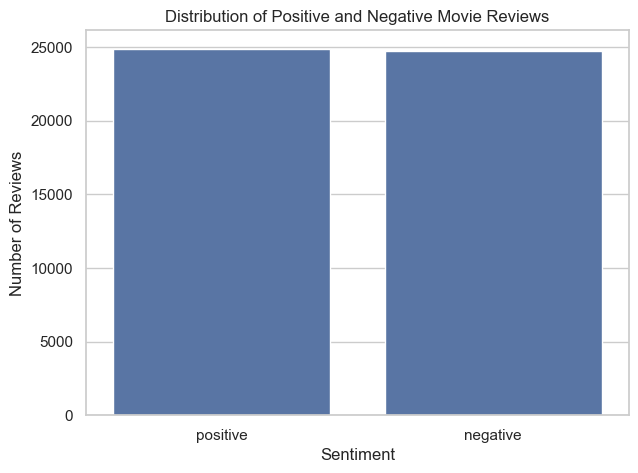

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentiment")

plt.title("Distribution of Positive and Negative Movie Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


In [4]:
# Descriptive statistics for review length
print("Review length statistics by sentiment:\n")

display(
    df.groupby("sentiment")[["word_count", "char_count"]]
      .agg(["mean", "median", "std", "min", "max"])
      .round(2)
)


Review length statistics by sentiment:



word_count                          char_count                      \
                mean median     std min   max       mean median      std min   
sentiment                                                                      
negative      227.24  173.0  163.34   4  1491    1271.55  958.0   929.00  32   
positive      230.86  171.0  175.94  10  2459    1304.42  953.0  1015.45  65   

                  
             max  
sentiment         
negative    8698  
positive   13593

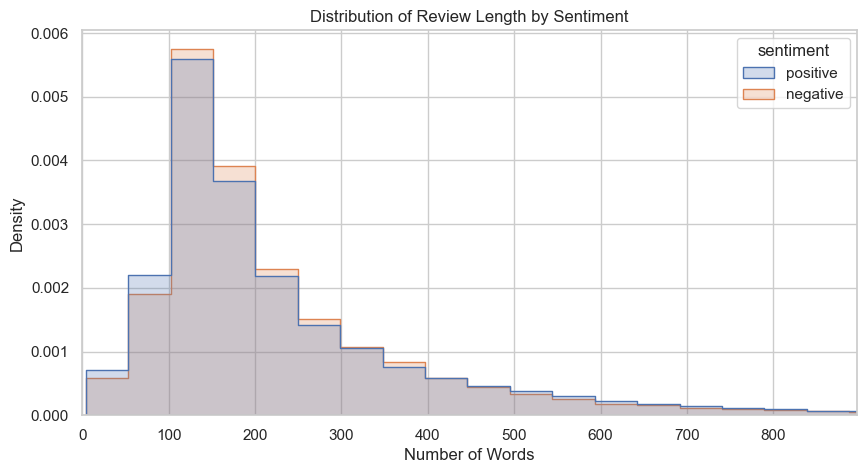

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, df["word_count"].quantile(0.99))
plt.title("Distribution of Review Length by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.show()


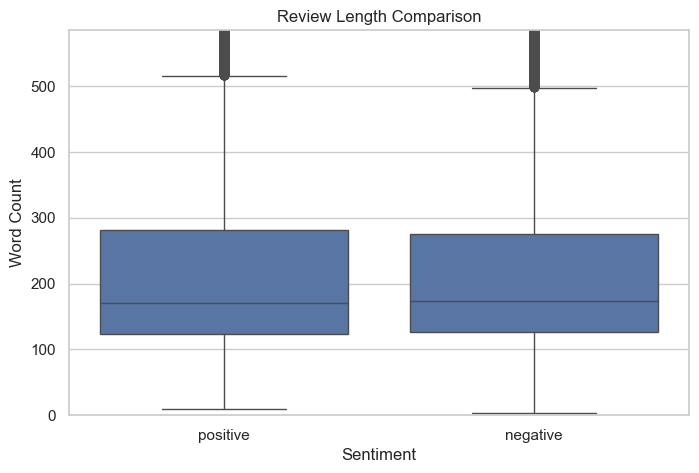

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.ylim(0, df["word_count"].quantile(0.95))
plt.title("Review Length Comparison")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")
plt.show()


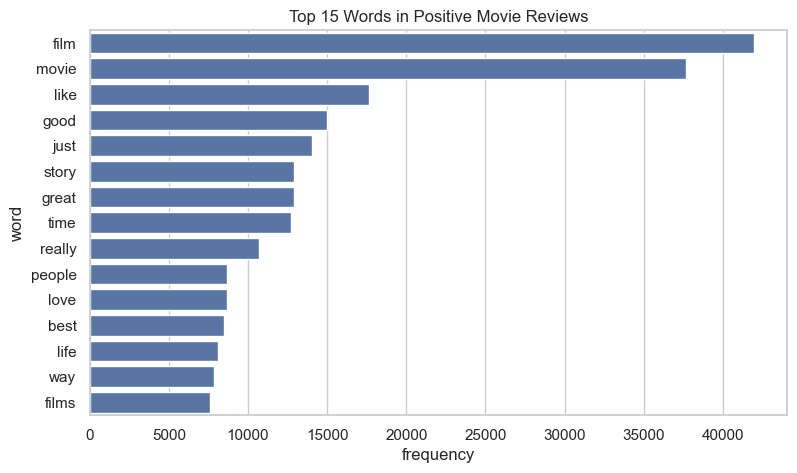

In [7]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def get_top_words(texts, n=15):
    words = []

    for text in texts:
        tokens = re.findall(r"\b[a-zA-Z]{3,}\b", text.lower())
        words.extend(
            word for word in tokens
            if word not in ENGLISH_STOP_WORDS
        )

    return Counter(words).most_common(n)

positive_words = get_top_words(
    df.loc[df["sentiment"] == "positive", "review"]
)

positive_df = pd.DataFrame(
    positive_words, columns=["word", "frequency"]
)

plt.figure(figsize=(9, 5))
sns.barplot(data=positive_df, x="frequency", y="word")
plt.title("Top 15 Words in Positive Movie Reviews")
plt.show()


In [ ]:
negative_words = get_top_words(
    df.loc[df["sentiment"] == "negative", "review"]
)

negative_df = pd.DataFrame(
    negative_words, columns=["word", "frequency"]
)

plt.figure(figsize=(9, 5))
sns.barplot(data=negative_df, x="frequency", y="word")
plt.title("Top 15 Words in Negative Movie Reviews")
plt.show()